# Links 
github repo: https://github.com/vildeskobba/IND320vilde 

Streamlit app: https://ind320vilde.streamlit.app/ 

Panopto_video: https://nmbu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=c6e4e0cf-fa1d-48e0-b01d-b4cf01398473 


In [1]:
%pip install -q -r requirements.txt
%pip install --upgrade certifi pymongo

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pyspark
from pyspark.sql import SparkSession
from cassandra.cluster import Cluster
from pymongo import MongoClient
import certifi
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import os
from dotenv import load_dotenv
from pyspark.sql.functions import sum, col, date_trunc
import matplotlib.pyplot as plt



In [3]:
from NVE_API import get_nve_data
from ENTSOE_API import get_entsoe_data

In [4]:
# Retrieve reservoir data from NVE API
df_nve = get_nve_data()

# Inspect the dataset
print("Dataset shape:", df_nve.shape)
display(df_nve.head())

Dataset shape: (14922, 11)


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,0001-01-01T00:00:00,0.614288,0.002160
1,1995-01-08,VASS,2,1995,1,0.608856,23.237715,14.148431,0001-01-01T00:00:00,0.744693,-0.135837
2,1995-01-08,VASS,3,1995,1,0.566906,28.155403,15.961480,0001-01-01T00:00:00,0.661432,-0.094525
3,1995-01-08,VASS,1,1995,1,0.635440,36.044464,22.904102,0001-01-01T00:00:00,0.756482,-0.121041
4,1995-01-08,NO,0,1995,1,0.607988,87.437580,53.161003,0001-01-01T00:00:00,0.752631,-0.144643


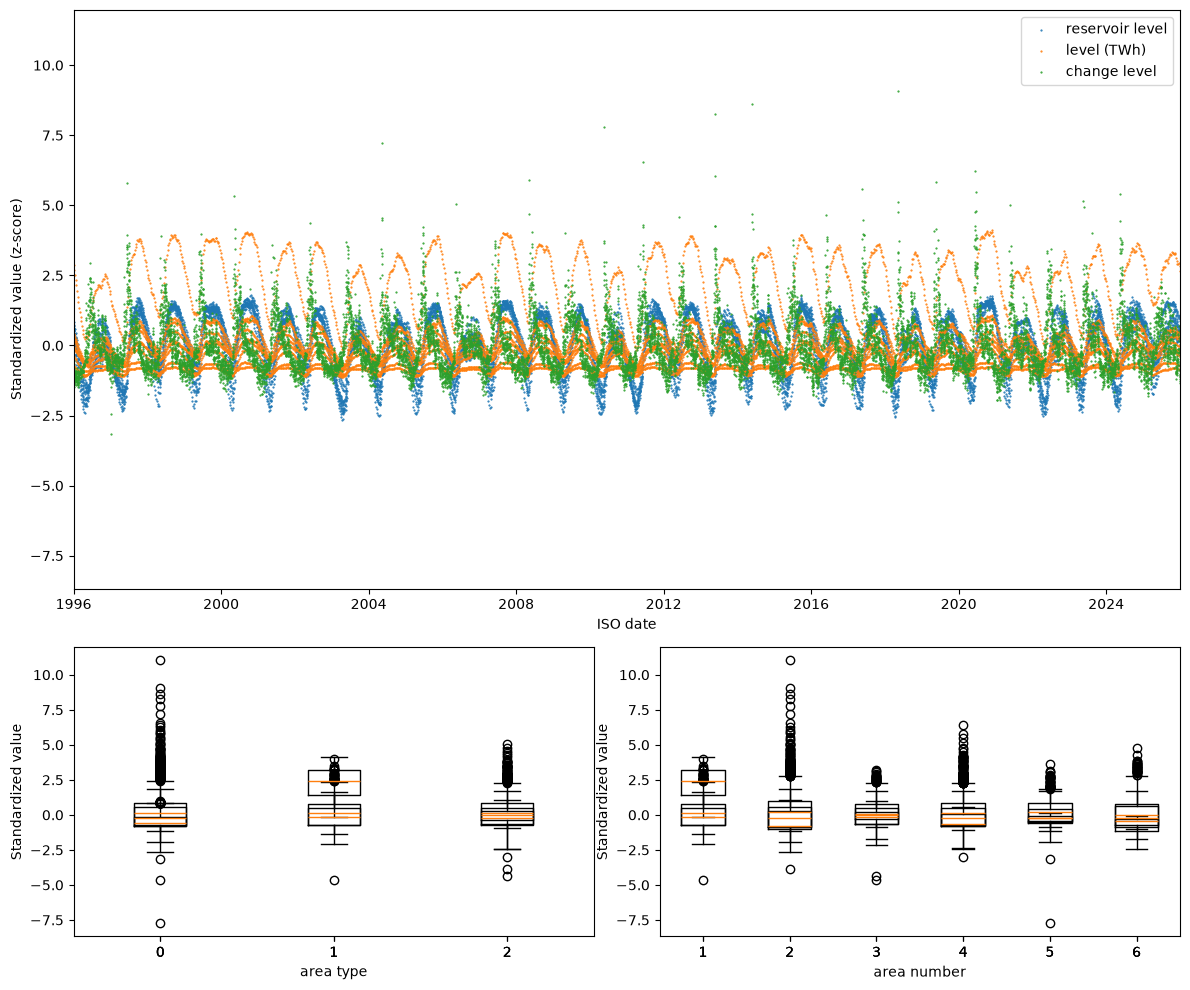

In [5]:
# recreating plots from from ca_1 

# 2. Rename headers to English and understandable.
df_nve.columns = [
    'date',
    'area type',
    'area number',
    'year (ISO)',
    'week (ISO)',
    'reservoir level',
    'capacity (TWh)',
    'level (TWh)',
    'next publishing date',
    'reservoir level last week',
    'change level'
]

y_axis_cols = [    
    'reservoir level',
    'level (TWh)',
    'change level'
    ]

# Standardize each variable separately
df_scaled = df_nve.copy()
df_scaled[y_axis_cols] = StandardScaler().fit_transform(df_nve[y_axis_cols])

fig = plt.figure(figsize=(12, 10))
gs = fig.add_gridspec(2, 2, height_ratios=[2, 1])

# 1. All variables over time
ax = fig.add_subplot(gs[0, :])

for column in y_axis_cols:
    ax.scatter(
        df_scaled["date"],
        df_scaled[column],
        s=0.3,
        label=column
    )
    ax.set_xlim(pd.Timestamp("1996-01-01"), 
                pd.Timestamp("2026-01-01"))

ax.set_xlabel("ISO date")
ax.set_ylabel("Standardized value (z-score)")
ax.legend()


# 2. All variables by area type
ax = fig.add_subplot(gs[1, 0])

for i, column in enumerate(y_axis_cols):
    data = [
        group[column].dropna()
        for _, group in df_scaled.groupby("area type")
    ]

    # offset positions so boxplots don't overlap
    positions = range(len(data))
    ax.boxplot(data, positions=positions)

ax.set_xlabel("area type")
ax.set_ylabel("Standardized value")


# 3. All variables by area number
ax = fig.add_subplot(gs[1, 1])

for column in y_axis_cols:
    data = [
        group[column].dropna()
        for _, group in df_scaled.groupby("area number")
    ]

    ax.boxplot(data)

ax.set_xlabel("area number")
ax.set_ylabel("Standardized value")

plt.tight_layout()
plt.show()

In [6]:
cluster = Cluster(["127.0.0.1"], port=9042)
session = cluster.connect("my_first_keyspace")

session.execute("""
    CREATE TABLE IF NOT EXISTS crossborder_flows (
        from_zone text,
        to_zone text,
        timestamp timestamp,
        flow_mw double,
        PRIMARY KEY ((from_zone, to_zone), timestamp)
    )
""")

print("Cassandra connected; table is ready.")

Cassandra connected; table is ready.


In [7]:
# if this fails, try restarting the kernel 

spark = SparkSession.builder \
    .appName("CassandraSparkTest") \
    .master("local[*]") \
    .config(
        "spark.jars.packages",
        "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1"
    ) \
    .config("spark.cassandra.connection.host", "127.0.0.1") \
    .config("spark.cassandra.connection.port", "9042") \
    .getOrCreate()

print("Spark session ready.")

26/10/20 13:48:53 WARN Utils: Your hostname, Mkken.local resolves to a loopback address: 127.0.0.1; using 172.20.10.3 instead (on interface en0)
26/10/20 13:48:53 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Ivy Default Cache set to: /Users/vildeskobba/.ivy2/cache
The jars for the packages stored in: /Users/vildeskobba/.ivy2/jars
com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-20ad6a13-6481-448b-a8c3-dea758ea4640;1.0
	confs: [default]


:: loading settings :: url = jar:file:/Users/vildeskobba/Desktop/IND320/IND320_vilde/.venv311/lib/python3.11/site-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


	found com.datastax.spark#spark-cassandra-connector_2.12;3.5.1 in central
	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.5.1 in central
	found org.scala-lang.modules#scala-collection-compat_2.12;2.11.0 in central
	found org.apache.cassandra#java-driver-core-shaded;4.18.1 in central
	found com.datastax.oss#native-protocol;1.5.1 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central
	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in central
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhistogram#HdrHistogram;2.1.12 in central
	found org.reactivestreams#reactive-streams;1.0.3 in central
	found org.apache.cassandra#java-driver-mapper-runtime;4.18.1 in central
	found org.apache.cassandra#java-driver-query-builder;4.18.1 in central
	found org.apache.commons#commons-lang3;3.10 in central
	found com.thoughtworks.paranamer#paranamer;2.8 in central
	found org.scala-lang#scala-reflect

Spark session ready.


In [8]:
load_dotenv("/Users/vildeskobba/Desktop/IND320/IND320_vilde/.env")
entsoe_api_token = os.getenv("ENTSOE_API_TOKEN")
if not entsoe_api_token:
    raise ValueError("ENTSOE_API_TOKEN not found in .env")

# border_data = {
#     ("NO_1", "SE_3"): None,
#     ("NO_2", "DK_1"): None,
#     ("NO_2", "NL"): None,
#     ("NO_2", "DE_LU"): None,
#     ("NO_2", "GB"): None,
#     ("NO_3", "SE_2"): None,
#     ("NO_4", "SE_2"): None,
# }


In [9]:
# border_data[("NO_1", "SE_3")] = get_entsoe_data(
#     entsoe_api_token, "NO_1", "SE_3"
# )

# df_no2_dk_1 = get_entsoe_data(
#     entsoe_api_token, "NO_2", "DK_1"
# ) 

# df_no2_nl = get_entsoe_data(
#     entsoe_api_token, "NO_2", "NL"
# ) 

# df_no2_delu = get_entsoe_data(
#     entsoe_api_token, "NO_2", "DE_LU"
# ) 

# df_no2_gb = get_entsoe_data(
#     entsoe_api_token, "NO_2", "GB"
# ) 

# df_no3_se2 = get_entsoe_data(
#     entsoe_api_token, "NO_3", "SE_2"
# ) 

# df_no4_se2 = get_entsoe_data(
#     entsoe_api_token, "NO_4", "SE_2"
# ) 


In [10]:

def insert_pandas_df_to_cassandra(df):
    df = df.rename(columns={"flow_MW": "flow_mw"})

    df["timestamp"] = pd.to_datetime(
        df["timestamp"], utc=True
    ).dt.tz_localize(None)

    spark_df = spark.createDataFrame(df)

    spark_df.write \
        .format("org.apache.spark.sql.cassandra") \
        .options(
            keyspace="my_first_keyspace",
            table="crossborder_flows"
        ) \
        .mode("append") \
        .save()

    print("Data inserted into Cassandra.") 

# insert_pandas_df_to_cassandra(df_no4_se2)

In [11]:
def check_df(zone_a, zone_b):
    check_df = spark.read \
        .format("org.apache.spark.sql.cassandra") \
        .options(
            keyspace="my_first_keyspace",
            table="crossborder_flows"
        ) \
        .load()

    check_df.filter(
        (check_df.from_zone == zone_a) &
        (check_df.to_zone == zone_b)
    ).show(10, truncate=False) 

    check_df.filter(
        (check_df.from_zone == zone_b) &
        (check_df.to_zone == zone_a)
    ).show(10, truncate=False) 

check_df("NO_4", "SE_2")

+---------+-------+-------------------+-------+
|from_zone|to_zone|timestamp          |flow_mw|
+---------+-------+-------------------+-------+
|NO_4     |SE_2   |2024-10-19 22:00:00|0.0    |
|NO_4     |SE_2   |2024-10-19 23:00:00|0.0    |
|NO_4     |SE_2   |2024-10-20 00:00:00|0.0    |
|NO_4     |SE_2   |2024-10-20 01:00:00|0.0    |
|NO_4     |SE_2   |2024-10-20 02:00:00|0.0    |
|NO_4     |SE_2   |2024-10-20 03:00:00|0.0    |
|NO_4     |SE_2   |2024-10-20 04:00:00|0.0    |
|NO_4     |SE_2   |2024-10-20 05:00:00|0.0    |
|NO_4     |SE_2   |2024-10-20 06:00:00|0.0    |
|NO_4     |SE_2   |2024-10-20 07:00:00|0.0    |
+---------+-------+-------------------+-------+
only showing top 10 rows

+---------+-------+-------------------+--------+
|from_zone|to_zone|timestamp          |flow_mw |
+---------+-------+-------------------+--------+
|SE_2     |NO_4   |2024-10-19 22:00:00|83.58   |
|SE_2     |NO_4   |2024-10-19 23:00:00|107.735 |
|SE_2     |NO_4   |2024-10-20 00:00:00|108.1675|
|SE_2   

In [12]:
'''This was how i tried fetching the data forst, connection was too 
unstable, so i decided to retrieve one border at a time'''

# for (zone_a, zone_b) in border_data:
#     df = get_entsoe_data(entsoe_api_token, zone_a, zone_b)
#     border_data[(zone_a, zone_b)] = df

'This was how i tried fetching the data forst, connection was too \nunstable, so i decided to retrieve one border at a time'

+---------+-------+------------------+
|from_zone|to_zone|          total_mw|
+---------+-------+------------------+
|     SE_2|   NO_4|322156.70528999995|
|     NO_4|   SE_2|1052466.2356130006|
+---------+-------+------------------+



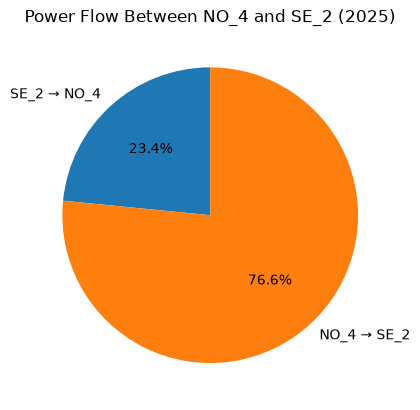

In [13]:
from pyspark.sql.functions import sum, col, date_trunc

connection_name = "NO4_SE2"
year = 2025

df = spark.read \
        .format("org.apache.spark.sql.cassandra") \
        .options(
            keyspace="my_first_keyspace",
            table="crossborder_flows"
        ) \
        .load()

pie_df = df.filter(
    (
        (col("from_zone") == "NO_4") &
        (col("to_zone") == "SE_2")
    ) |
    (
        (col("from_zone") == "SE_2") &
        (col("to_zone") == "NO_4")
    )
).filter(
    (col("timestamp") >= "2025-01-01") &
    (col("timestamp") < "2026-01-01")
).groupBy(
    "from_zone", "to_zone"
).agg(
    sum("flow_mw").alias("total_mw")
)

pie_df.show()

pdf = pie_df.toPandas()

plt.pie(
    pdf["total_mw"],
    labels=pdf["from_zone"] + " → " + pdf["to_zone"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Power Flow Between NO_4 and SE_2 (2025)")
plt.show()

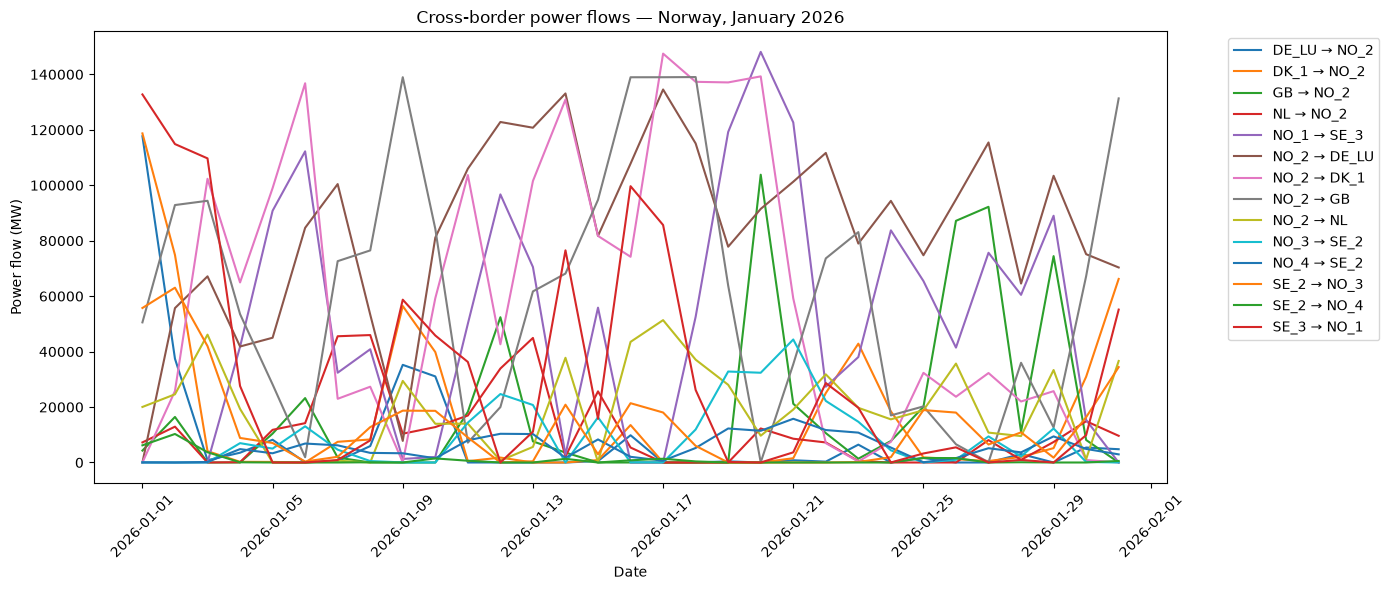

In [14]:
from pyspark.sql.functions import col

january_df = df.filter(
    (col("timestamp") >= "2026-01-01") &
    (col("timestamp") < "2026-02-01")
).select(
    "timestamp",
    "from_zone",
    "to_zone",
    "flow_mw"
).orderBy("timestamp")

from pyspark.sql.functions import sum
import matplotlib.pyplot as plt
import pandas as pd

line_df = january_df.groupBy(
    date_trunc("day", col("timestamp")).alias("timestamp"), #time resolution set to day
    "from_zone", 
    "to_zone"
).agg(
    sum("flow_mw").alias("flow_mw")
).orderBy("timestamp")

pdf = line_df.toPandas()
pdf["timestamp"] = pd.to_datetime(pdf["timestamp"])

plt.figure(figsize=(14, 6))

for (from_zone, to_zone), group in pdf.groupby(
    ["from_zone", "to_zone"]
):
    plt.plot(
        group["timestamp"],
        group["flow_mw"],
        label=f"{from_zone} → {to_zone}"
    )

plt.xlabel("Date")
plt.ylabel("Power flow (MW)")
plt.title("Cross-border power flows — Norway, January 2026") 
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [15]:
uri = os.getenv("MONGO_URI")
client = MongoClient(
    uri,
    tlsCAFile=certifi.where()
)

print(client.admin.command("ping"))

{'ok': 1}


In [16]:
db = client["power_data"]

annual_collection = db["annual_flows"]

annual_collection.insert_many(
    pie_df.toPandas().to_dict("records")
)

print("Annual data inserted:", annual_collection.count_documents({}))

Annual data inserted: 4


In [17]:
january_collection = db["january_2026_flows"]

january_collection.insert_many(
    line_df.toPandas().to_dict("records")
)

print("January data inserted:", january_collection.count_documents({}))

26/10/20 13:49:06 WARN GarbageCollectionMetrics: To enable non-built-in garbage collector(s) List(G1 Concurrent GC), users should configure it(them) to spark.eventLog.gcMetrics.youngGenerationGarbageCollectors or spark.eventLog.gcMetrics.oldGenerationGarbageCollectors


January data inserted: 868
